# **Project Title: Cardiovascular Disease Prediction**

---


###**problem addressed : Early detection of heart issues Heart disease is the leading cause of death worldwide. Traditional diagnosis, relying on physician expertise or tests, is time-consuming and prone to human error, whether in interpreting results or in traditional or clinical examinations.**


---


### **practical objective : Therefore, the need arose for an assistant to help doctors make better decisions for patients. Consequently, a classification model was developed that uses a random forest algorithm to analyze patients' vital data. The output shows whether the patient is affected or not.**


---


# Team Member:
# Haitham Hani Dalloul
# Mahmoud Fayez Khader


# **Data Source**
### **The data was downloaded from Kaggle, which is a vast data repository.**
# **Justification**
### **The dataset was chosen because it contains real medical data, including 70,000 points,It is a dataset dedicated to cardiovascular disease research.  and covers key vital signs such as blood pressure, cholesterol, and age.**
# **Main Characteristics**
Number of Features : 12 features

Number of Classes 2 classes (0: Healthy, 1: Cardiovascular Disease)

Features
1. Age| age | int (days)   
2. Height  | height | int (cm) |
3. Weight | weight | float (kg) |
4. Gender | gender | categorical code |
5. Systolic blood pressure | ap_hi | int |
6. Diastolic blood pressure  | ap_lo | int |
7. Cholesterol | cholesterol| 1: normal, 2: above normal, 3: well above normal |
8. Glucose   | gluc | 1: normal, 2: above normal, 3: well above normal |
9. Smoking | smoke | binary |
10. Alcohol intake  | alco | binary |
11. Physical activity  | active | binary |
12. Presence or absence of cardiovascular disease | cardio | binary |






# **Step 1: Import  Libraries**

In [ ]:
# Libraries for data manipulation
import pandas as pd
import numpy as np
#Libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Machine learning utilites
import sklearn as sk
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# **Step 2: Load Dataset Selected**

In [ ]:
#from google.colab import drive

# Connecting Google Drive
#drive.mount('/content/drive')

# File path on Drive
#file_path = '/content/drive/MyDrive/Colab Notebooks/project/cardio_train.csv'

# Reading the data
#df = pd.read_csv(file_path)
import pandas as pd

# لو في نفس مجلد المشروع
#df = pd.read_csv("cardio_train.csv")

# لو في مسار كامل
df = pd.read_csv(r"cardio_train.csv")

In [ ]:
#from google.colab import sheets
#sheet = sheets.InteractiveSheet(df=df)

## **Step 3: Data Exploration**

In [ ]:
# Display the number of rows and columns
print(f"Number of records : {df.shape[0]}")
print(f"Number of properties: {df.shape[1]}\n")

# Check for missing values in each column
print(df.isnull().sum())

# Displaying the first 5 rows after editing
print("Current data format:")
display(df.head())

Number of records : 70000
Number of properties: 1

id;age;gender;height;weight;ap_hi;ap_lo;cholesterol;gluc;smoke;alco;active;cardio    0
dtype: int64
Current data format:


,id;age;gender;height;weight;ap_hi;ap_lo;cholesterol;gluc;smoke;alco;active;cardio
0,0;18393;2;168;62.0;110;80;1;1;0;0;1;0
1,1;20228;1;156;85.0;140;90;3;1;0;0;1;1
2,2;18857;1;165;64.0;130;70;3;1;0;0;0;1
3,3;17623;2;169;82.0;150;100;1;1;0;0;1;1
4,4;17474;1;156;56.0;100;60;1;1;0;0;0;0


# **Step 4:Data Preprocessing**

## **1. Data Cheaking**

In [ ]:
# Using sep=';' because the pandas library considers ','
# a comma, but it's different here, so we specified the comma for it.
df = pd.read_csv(r"cardio_train.csv", sep=';')

# Display the number of rows and columns
print(f"Number of records : {df.shape[0]}")
print(f"Number of properties: {df.shape[1]}\n")

# Displaying the first 5 rows after editing
print("Current data format:")
display(df.head())

# Check for missing values in each column
print(df.isnull().sum())

# The ID column was removed because it does not affect the prediction.
df.drop('id', axis=1, inplace=True)



Number of records : 70000
Number of properties: 13

Current data format:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


In [ ]:
# Quick statistical description of the data
df.describe()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


## **2. Handling Outliers**

In [ ]:
# 1.Clearing up illogical blood pressure readings
df = df[(df['ap_hi'] < 250) & (df['ap_hi'] > 40)]
df = df[(df['ap_lo'] < 200) & (df['ap_lo'] > 40)]

print(f"Number of records after cleaning: {len(df)}")

Number of records after cleaning: 68759


In [ ]:
#2. 0 for females, 1 for males (optional but professional)
df['gender'] = df['gender'].replace({1: 0, 2: 1})

In [ ]:
# 3. Converting age from days to years (because it is given in days 18393)
df['age'] = (df['age'] / 365).round().astype(int)

# **Step 5:Training & Testing Split**

In [ ]:
# Defining the features (X) and the goal (y)
X = df.drop('cardio', axis=1) # All columns except cardio
y = df['cardio'] # The column we want to predict

# Data segmentation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data size: {X_train.shape}")
print(f"Test data size: {X_test.shape}")

Training data size: (55007, 11)
Test data size: (13752, 11)


# **Step 6: Scaling**

In [ ]:

# Scaling - For digital columns only
scaler = StandardScaler()
# We apply standardization to training and testing data.
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# **Step 7:Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1.Creating the model (we set the number of trees to 100)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)

# 2.Training the model using training data
rf_model.fit(X_train, y_train)

# 3.Prediction using test data
y_pred = rf_model.predict(X_test)

# 4.Calculating accuracy and results
accuracy = accuracy_score(y_test, y_pred)
print(f"--- Overall model accuracy: {accuracy * 100:.2f}% ---")
print("\nDetailed classification report :")
print(classification_report(y_test, y_pred))

--- Overall model accuracy: 73.50% ---

Detailed classification report :
              precision    recall  f1-score   support

           0       0.72      0.79      0.75      6967
           1       0.76      0.68      0.72      6785

    accuracy                           0.74     13752
   macro avg       0.74      0.73      0.73     13752
weighted avg       0.74      0.74      0.73     13752



# **Step 8:Performance Evaluation**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#Calculating Performance Evaluation
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.7350
Precision: 0.7570
Recall: 0.6818
F1-Score: 0.7174


# **Step 9:Visualization**

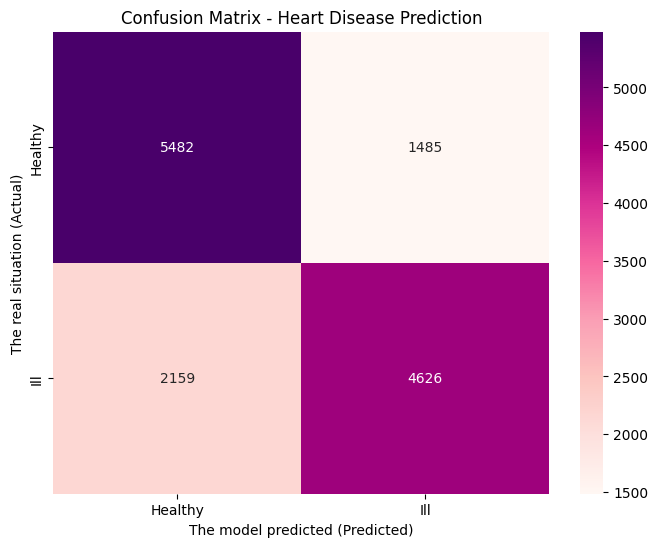

In [ ]:
# Drawing the Confusion Matrix
plt.figure(figsize=(8,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu', xticklabels=['Healthy', 'Ill'], yticklabels=['Healthy', 'Ill'])
plt.xlabel('The model predicted (Predicted)')
plt.ylabel('The real situation (Actual)')
plt.title('Confusion Matrix - Heart Disease Prediction')
plt.show()

# **Results Analysis & Conclusion**
Results Analysis & Conclusion
1. Model Performance: The Random Forest model achieved an accuracy of approximately 73%. The Confusion Matrix shows that the model is effective in identifying true positive cases (patients with heart disease), as indicated by the high Recall score.

2. Strengths:

Robustness: Using Random Forest prevents overfitting compared to a single Decision Tree.

Data Handling: The model successfully handled a large dataset (70,000 records) with complex features like blood pressure.

3. Limitations:

Overlap: There is some misclassification between healthy and diseased patients, likely due to overlapping symptoms in blood pressure readings.

Features: Adding more lifestyle features (e.g., diet, stress levels) could improve accuracy further.